---
title: "Formatting Text with f-strings"
subtitle: "DS 2023 | Communicating with Data"
---

## Overview

An essential part of visualization is **the use of text** &mdash; words and sentences.

Text appears in **many places**: titles, labels, legends, and annotations.

Sometimes text **comes from the data**, such as the name of the busiest month or the value of a mean.

Other times, **text is added** to emphasize a point about a visualization or to add essential context.

Python provides a useful tool to create text that dynamically incorporates the data presented in the visualization: formatted strings call **f-strings**.

An f-string is created by placing an `f` in front of the opening quote and inserting variables in the string with braces `{}`.

Anything inside braces is **evaluated** as Python code and the resulting value is written into the string.

The process of evaluating variables within strings is called **interpolation**.

```{note}
f-strings were added in Python 3.6 back in 2016.

Before that, other methods were used to interpolate data into strings.
```

## Putting Values into Strings

Let's look at some simple examples.

First, we'll import our usual libraries and some familiar datasets.

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

penguins = sns.load_dataset('penguins').dropna()
flights = sns.load_dataset('flights')

Here is the simplest case.

In [46]:
species = 'Gentoo'
count = 119

f'There are {count} {species} penguins.'

'There are 119 Gentoo penguins.'

Without the `f`, Python treats the braces as ordinary characters.

In [47]:
'There are {count} {species} penguins.'

'There are {count} {species} penguins.'

The braces can hold any **expression**, not just a variable name.

An expression is any piece of code that produces a value.

In [48]:
f'There are {len(penguins)} penguins represented in the dataset, and {penguins.species.nunique()} species.'

'There are 333 penguins represented in the dataset, and 3 species.'

In [49]:
f'The heaviest penguin weighs {penguins.body_mass_g.max() / 1000} kg.'

'The heaviest penguin weighs 6.3 kg.'

```{tip}
This is what makes f-strings useful for plotting.

The text is computed from the data, so it stays correct when the data change.
```

## Formatting Numbers

The effective use of text requires that it be formatted properly for readers.

Take, for example, the mean of body mass.

In [50]:
mean_mass = penguins.body_mass_g.mean()

f'Mean body mass: {mean_mass} g'

'Mean body mass: 4207.057057057057 g'

A dozen decimal places on a plot is inelegant and not very readable.

It may also give the wrong impression about how precise your measurements are.

We can control how a value is written by adding a colon after the variable and then providing a **format specification** inside the braces.

For example:

In [51]:
f'Mean body mass: {mean_mass:.0f} g'

'Mean body mass: 4207 g'

`.0f` means: write it as a fixed-point number with 0 decimal places.

Notice that the value is rounded, not cut off.

**Here are some frequently use format specifications:**

| Spec | Means | `{x:spec}` with `x = 4207.057` |
|---|---|---|
| `.2f` | 2 decimal places | `4207.06` |
| `.0f` | no decimal places | `4207` |
| `,` | a comma between thousands | `4,207.057` |
| `,.0f` | commas and no decimals | `4,207` |
| `.1%` | multiply by 100, add `%`, 1 decimal | (for `x = 0.157`) `15.7%` |
| `.2e` | scientific notation | `4.21e+03` |
| `+.1f` | always show the sign | `+4207.1` |
| `d` | an integer (for `int` values only) | (for `x = 42`) `42` |

Let's look at a few examples.

In [67]:
x = 4207.057
share = 0.157

print(f'{x:.2f}')
print(f'{x:,.0f}')
print(f'{share:.1%}')
print(f'{x:.2e}')
print(f'{-x:+.1f}  {x:+.1f}')

4207.06
4,207
15.7%
4.21e+03
-4207.1  +4207.1


```{caution}
The order inside a specification matters: the comma comes before the precision, as in `,.0f`.
```

### Width and alignment

A number before the precision sets a minimum **width**, padding with spaces.

`<`, `>`, and `^` align left, right, and center.

This is useful for lining up printed tables.

In [68]:
for s, g in penguins.groupby('species').body_mass_g:
    print(f'{s:<10} {g.mean():>8,.1f} g   ({len(g):>3} birds)')

Adelie      3,706.2 g   (146 birds)
Chinstrap   3,733.1 g   ( 68 birds)
Gentoo      5,092.4 g   (119 birds)


## Formatting Dates

Dates have their own specification language.

It uses **directives** that start with `%`.

In [54]:
date = pd.Timestamp('1960-07-01')

print(f'{date:%B %Y}')
print(f'{date:%b %Y}')
print(f'{date:%Y-%m-%d}')
print(f'{date:%d/%m/%y}')

July 1960
Jul 1960
1960-07-01
01/07/60


| Directive | Means | Example |
|---|---|---|
| `%Y` | four-digit year | `1960` |
| `%y` | two-digit year | `60` |
| `%B` | full month name | `July` |
| `%b` | abbreviated month | `Jul` |
| `%m` | month number | `07` |
| `%d` | day of the month | `01` |
| `%A` | weekday | `Friday` |

```{note}
These are the same directives used by `strftime()` and by `pd.to_datetime(..., format=...)`.
```

## Three Things That Trip People Up

**Quotes inside the braces.**
To look up a column inside an f-string, use the other kind of quote.

In [55]:
row = penguins.iloc[0]

f"The first penguin is an {row['species']} from {row['island']}."

'The first penguin is an Adelie from Torgersen.'

If the f-string uses double quotes, use single quotes inside, and the other way round.

**Literal braces.**
To write a brace itself, double it.

In [56]:
f'A set looks like {{1, 2, 3}} and has {len({1, 2, 3})} items.'

'A set looks like {1, 2, 3} and has 3 items.'

**Line breaks.**
`\n` inside any string starts a new line, which is handy for two-line labels.

In [57]:
print(f'Gentoo\nn = {count}')

Gentoo
n = 119


## A Shortcut for Checking Values

Adding `=` after an expression prints the expression and its value.

It saves typing when we are checking our work.

In [58]:
f'{mean_mass=:.1f}'

'mean_mass=4207.1'

## f-strings in Matplotlib

Can we use f-strings in plots?

Yes, anywhere Matplotlib accepts text.

That is because Matplotlib never sees the f-string itself.

Python fills in the braces first, and hands Matplotlib an ordinary, finished string.

| Text | Where it goes |
|---|---|
| `ax.set_title(f'...')` | the title of one axes |
| `ax.set_xlabel(f'...')`, `ax.set_ylabel(f'...')` | the axis labels |
| `fig.suptitle(f'...')` | a title over all the panels |
| `ax.text(x, y, f'...')` | text anywhere on the plot |
| `ax.annotate(f'...', xy=...)` | a callout with an arrow |
| `ax.plot(..., label=f'...')` | an entry in the legend |
| `ax.set_xticks(positions, labels=[f'...' for ...])` | the tick labels, one string each |

### Labels and titles from the data

Here we label each species' mean body mass on a bar chart, and put a computed finding in the title.

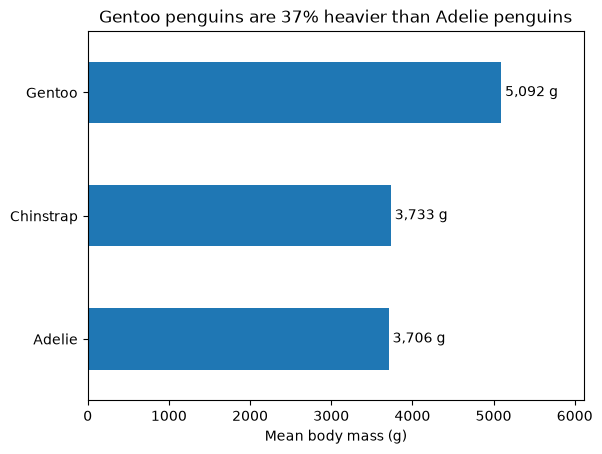

In [59]:
means = penguins.groupby('species').body_mass_g.mean().sort_values()

heaviest = means.index[-1]
lightest = means.index[0]

ratio = means.iloc[-1] / means.iloc[0]

ax = means.plot.barh(color='tab:blue')

for i, (s, m) in enumerate(means.items()):
    ax.text(m, i, f' {m:,.0f} g', va='center')

ax.set_title(f'{heaviest} penguins are {ratio - 1:.0%} heavier than {lightest} penguins')
ax.set_xlabel('Mean body mass (g)')
ax.set_ylabel('')
ax.set_xlim(0, means.max() * 1.2)
plt.show()

Every number on this plot came from the data.

If we filtered the data, the labels and the title would update themselves.

### Legend labels

The `label` of each series becomes its legend entry.

Here each entry also shows how many penguins are behind it.

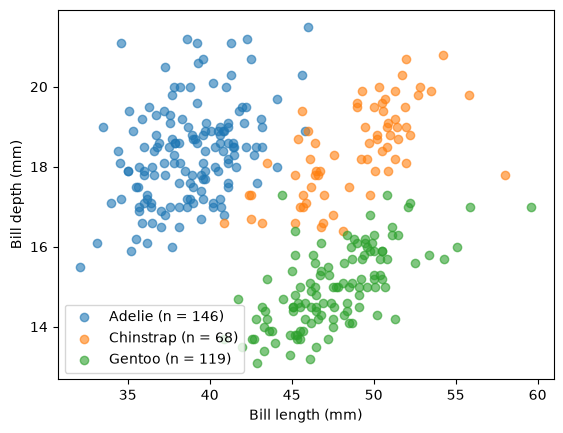

In [60]:
fig, ax = plt.subplots()

for s, group in penguins.groupby('species'):
    ax.scatter(group.bill_length_mm, group.bill_depth_mm, alpha=.6,
               label=f'{s} (n = {len(group)})')

ax.legend()
ax.set_xlabel('Bill length (mm)')
ax.set_ylabel('Bill depth (mm)')
plt.show()

### Dates in labels

Date directives work in plot text too.

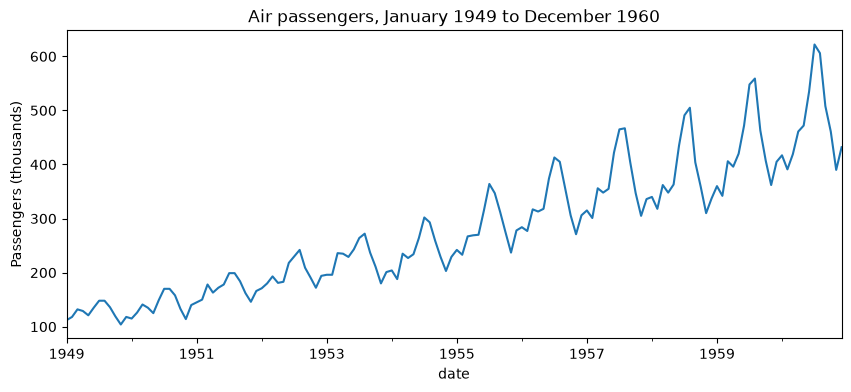

In [61]:
monthly = flights.assign(date=pd.to_datetime(flights.year.astype(str) + '-' + flights.month.astype(str), format='%Y-%b'))
monthly = monthly.set_index('date').passengers

ax = monthly.plot(figsize=(10, 4))
ax.set_title(f'Air passengers, {monthly.index.min():%B %Y} to {monthly.index.max():%B %Y}')
ax.set_ylabel('Passengers (thousands)')
plt.show()

### Snag 1: dollar signs

Matplotlib reads any text between two dollar signs as **math**, and draws it in a math font.

That is a problem for money.

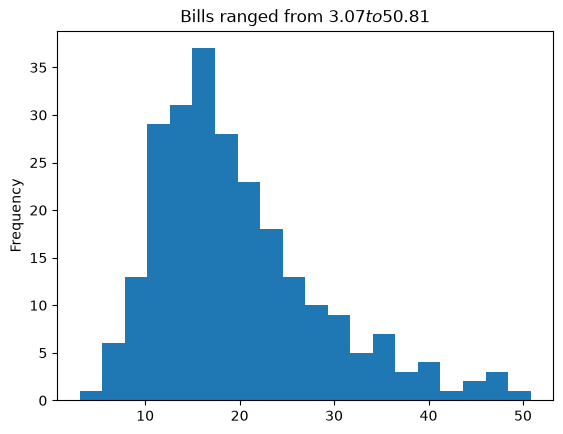

In [62]:
tips = sns.load_dataset('tips')
low, high = tips.total_bill.min(), tips.total_bill.max()

ax = tips.total_bill.plot.hist(bins=20)
ax.set_title(f'Bills ranged from ${low:.2f} to ${high:.2f}')
plt.show()

The dollar signs vanished, and the text between them came out in italics.

To get a literal dollar sign, put a backslash before it: `\$`.

Inside a Python string, a single backslash has its own meanings, so we write two, `\\$`, and Python passes one of them on to Matplotlib.

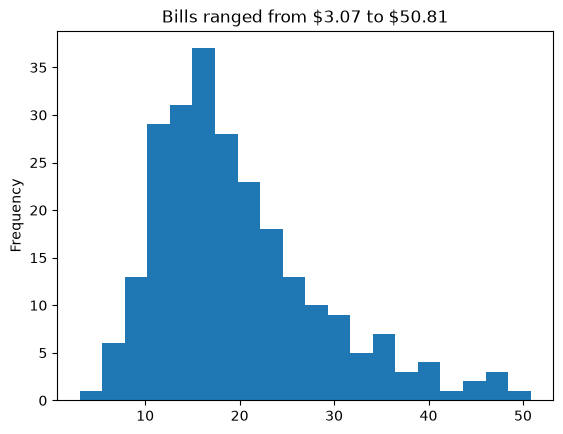

In [63]:
ax = tips.total_bill.plot.hist(bins=20)
ax.set_title(f'Bills ranged from \\${low:.2f} to \\${high:.2f}')
plt.show()

A single dollar sign on its own is safe.

The trouble starts when a label has two.

### Snag 2: braces in math

Sometimes we *want* math in a label, such as a Greek letter or a superscript.

Math text uses LaTeX, and LaTeX uses braces too: $R^{2}$ is written `$R^{2}$`.

Inside an f-string, braces mean "a value goes here", so LaTeX's braces must be **doubled**, as we saw for literal braces.

Here we compute the $R^2$ of a straight-line fit and put it in the title.

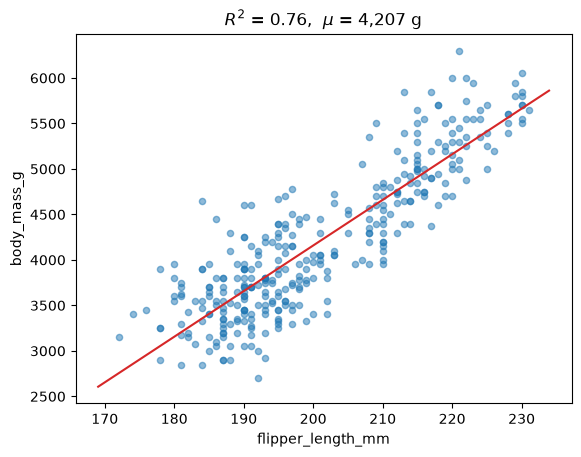

In [64]:
x_col, y_col = 'flipper_length_mm', 'body_mass_g'
slope, intercept = np.polyfit(penguins[x_col], penguins[y_col], 1)
r_squared = penguins[x_col].corr(penguins[y_col]) ** 2
mean_mass = penguins[y_col].mean()

ax = penguins.plot.scatter(x=x_col, y=y_col, alpha=.5)
xs = np.array(ax.get_xlim())
ax.plot(xs, intercept + slope * xs, color='tab:red')

ax.set_title(f'$R^{{2}}$ = {r_squared:.2f},  $\\mu$ = {mean_mass:,.0f} g')
plt.show()

Read the title code piece by piece.

- `$R^{{2}}$` becomes `$R^{2}$` once Python is done, which Matplotlib draws as R².
- `{r_squared:.2f}` is an ordinary f-string value.
- `$\\mu$` becomes `$\mu$`, which Matplotlib draws as the Greek letter μ. The backslash is doubled for the same reason as with the dollar sign.

```{tip}
Instead of doubling every backslash, we can put an `r` before the `f`, as in `rf'$\mu$ = {m:.0f}'`.
The `r` makes the string **raw**: backslashes are kept as they are.
The braces still have to be doubled, because the `f` still treats them as values.
```

### Snag 3: tick labels

Tick labels are different.

A plot has many ticks, and each needs its own label, computed from its own value.

So instead of a finished string, we give Matplotlib a **format string** and let it fill in each tick value.

It names that value `x`, and the string has **no** `f` in front.

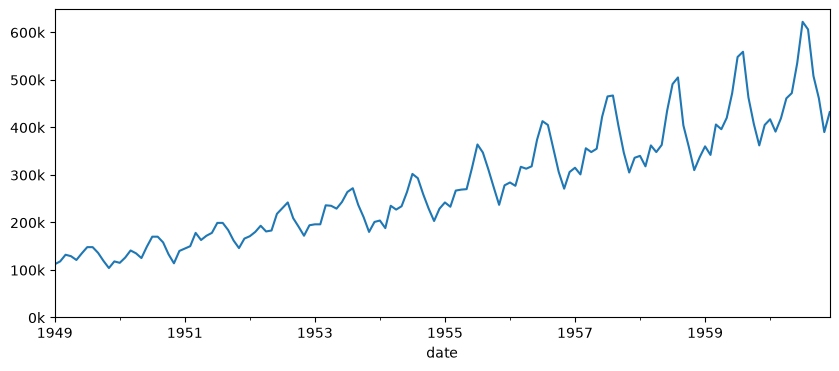

In [65]:
ax = monthly.plot(figsize=(10, 4))
ax.yaxis.set_major_formatter('{x:,.0f}k')
ax.set_ylim(0)
plt.show()

What happens if we add the `f` out of habit?

Python fills in the braces *immediately*, using whatever `x` happens to mean right now.

Earlier in this notebook, we set `x = 4207.057`.

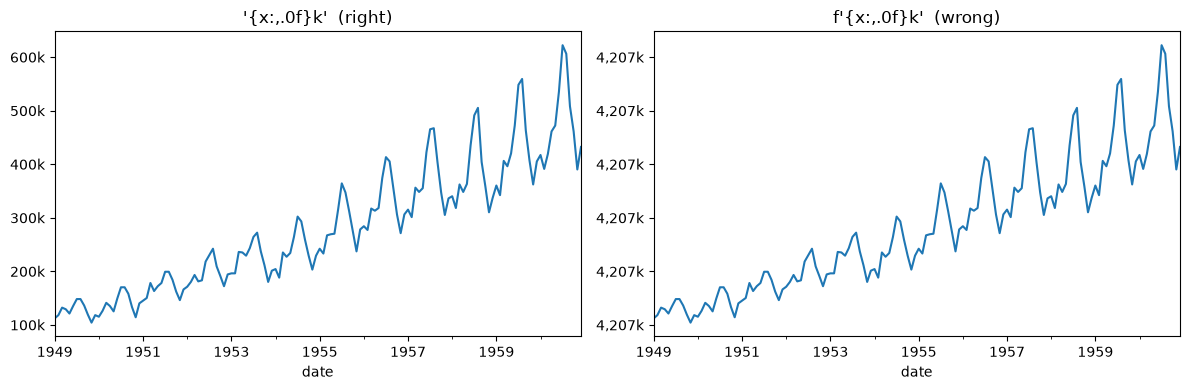

In [66]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

monthly.plot(ax=ax[0], title="'{x:,.0f}k'  (right)")
ax[0].yaxis.set_major_formatter('{x:,.0f}k')

monthly.plot(ax=ax[1], title="f'{x:,.0f}k'  (wrong)")
ax[1].yaxis.set_major_formatter(f'{x:,.0f}k')

plt.tight_layout()
plt.show()

On the right, every tick says the same thing.

The f-string turned into the finished text `'4,207k'` before Matplotlib ever saw it, so there was nothing left to fill in.

If `x` had not been defined at all, we would have gotten a `NameError` instead.

```{important}
For titles, labels, legends, and annotations, use an f-string: you supply the values.
For tick formatters, use a plain format string with `{x}`: Matplotlib supplies the values.
```

## The Same Specifications Elsewhere

The format specifications are a small language of their own, and other tools accept them too.

Like tick formatters, these take a plain format string, with no `f`.

| Where | Example |
|---|---|
| A string's `.format()` method | `'{:,.0f}'.format(4207.057)` |
| Pandas styled tables | `df.style.format('{:.1f}')` |
| Matplotlib bar labels | `ax.bar_label(ax.containers[0], fmt='{:,.0f}')` |
| Matplotlib tick labels | `ax.yaxis.set_major_formatter('{x:,.0f}')` |

```{note}
You will also see two older styles in other people's code: `'%.2f' % x` and `'{:.2f}'.format(x)`.
Both still work.
f-strings do the same job and are easier to read, so we use them in this course.
```

## Summary

- An f-string is a string with `f` before the quote. Expressions in `{ }` are evaluated and written into it.
- A colon after the expression starts a **format specification**: `{x:,.2f}`.
- Dates take `%` directives: `{date:%B %Y}`.
- Use the other kind of quote inside the braces, and double a brace to write it literally.
- f-strings work anywhere Matplotlib takes text: titles, labels, `text()`, `annotate()`, and legend labels.
- In plot text, write a literal dollar sign as `\\$`, and double the braces of any LaTeX math: `$R^{{2}}$`.
- Tick formatters, `bar_label(fmt=)`, `.format()`, and Pandas `style.format()` take a plain format string, with no `f`.

| To write... | Code | Result |
|---|---|---|
| a value | `f'{n} birds'` | `119 birds` |
| 1 decimal | `f'{x:.1f}'` | `4207.1` |
| thousands, no decimals | `f'{x:,.0f}'` | `4,207` |
| a percent | `f'{0.157:.1%}'` | `15.7%` |
| a signed change | `f'{0.3:+.1f}'` | `+0.3` |
| a month and year | `f'{date:%B %Y}'` | `July 1960` |
| a padded column | `f'{s:<10}'` | `Gentoo    ` |
| a check | `f'{x=:.1f}'` | `x=4207.1` |
| a dollar sign in a plot | `f'\\${v:.2f}'` | \$12.50 |
| math in a plot | `f'$R^{{2}}$ = {r2:.2f}'` | R² = 0.76 |
| tick labels (no `f`) | `'{x:,.0f}k'` | 600k |